In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

### Data Preprocessing

In [4]:
df = pd.read_csv('../Datasets/placement.csv')
df.sample(5)

,cgpa,placement_exam_marks,placed
484,5.81,18.0,Not Placed
572,7.66,37.0,Placed
298,6.16,48.0,Not Placed
56,6.93,15.0,Placed
896,5.73,38.0,Not Placed


In [5]:
df.shape

(1000, 3)

In [6]:
df.isnull().sum()

cgpa                    0
placement_exam_marks    0
placed                  0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(19)

In [8]:
df.fillna(df.mean(numeric_only=True), inplace=True)

,cgpa,placement_exam_marks,placed
0,7.19,26.0,Placed
1,7.46,38.0,Placed
2,7.54,40.0,Placed
3,6.42,8.0,Placed
4,7.23,17.0,Not Placed
...,...,...,...
995,8.87,44.0,Placed
996,9.12,65.0,Placed
997,4.89,34.0,Not Placed
998,8.62,46.0,Placed


In [9]:
df.drop_duplicates(inplace=True)
df.head(5)

,cgpa,placement_exam_marks,placed
0,7.19,26.0,Placed
1,7.46,38.0,Placed
2,7.54,40.0,Placed
3,6.42,8.0,Placed
4,7.23,17.0,Not Placed


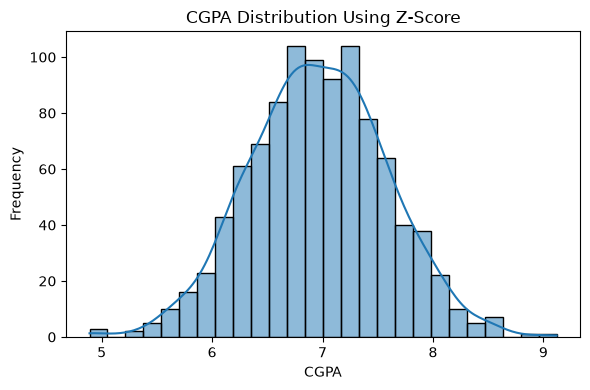

In [12]:
mean = df["cgpa"].mean()
std = df["cgpa"].std()

z = (df["cgpa"] - mean) / std
outliers_z = df[z.abs() > 3]

trimmed_z = df[z.abs() <= 3].copy()

lower_z = mean - 3 * std
upper_z = mean + 3 * std
capped_z = df.copy()
capped_z["cgpa"] = np.clip(capped_z["cgpa"], lower_z, upper_z)

plt.figure(figsize=(6, 4))
sns.histplot(df["cgpa"], kde=True)
plt.title("CGPA Distribution Using Z-Score")
plt.xlabel("CGPA")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()



In [13]:
Q1 = df["placement_exam_marks"].quantile(0.25)
Q3 = df["placement_exam_marks"].quantile(0.75)
IQR = Q3 - Q1

lower_iqr = Q1 - 1.5 * IQR
upper_iqr = Q3 + 1.5 * IQR

In [14]:
outliers_iqr = df[(df["placement_exam_marks"] < lower_iqr) | (df["placement_exam_marks"] > upper_iqr)]

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print("IQR Outliers:\n", outliers_iqr)
print("Number of Outliers:", len(outliers_iqr))

Q1: 17.0, Q3: 44.0, IQR: 27.0
IQR Outliers:
      cgpa  placement_exam_marks      placed
9    7.75                  94.0      Placed
40   6.60                  86.0      Placed
61   7.51                  86.0  Not Placed
134  6.33                  93.0  Not Placed
162  7.80                  90.0  Not Placed
283  7.09                  87.0  Not Placed
290  8.38                  87.0  Not Placed
311  6.97                  87.0      Placed
324  6.64                  90.0  Not Placed
630  6.56                  96.0      Placed
685  6.05                  87.0      Placed
730  6.14                  90.0      Placed
771  7.31                  86.0      Placed
846  6.99                  97.0  Not Placed
917  5.95                 100.0  Not Placed
Number of Outliers: 15


In [16]:
trimming_iqr = df[df["placement_exam_marks"].between(lower_iqr, upper_iqr)].copy()
print("Trimmed Data Shape:", trimming_iqr.shape)

Trimmed Data Shape: (966, 3)


In [17]:
capped_iqr = df.copy()
capped_iqr["placement_exam_marks"] = np.clip(capped_iqr["placement_exam_marks"], lower_iqr, upper_iqr)

print("Capped Data Shape:", capped_iqr.shape)

Capped Data Shape: (981, 3)


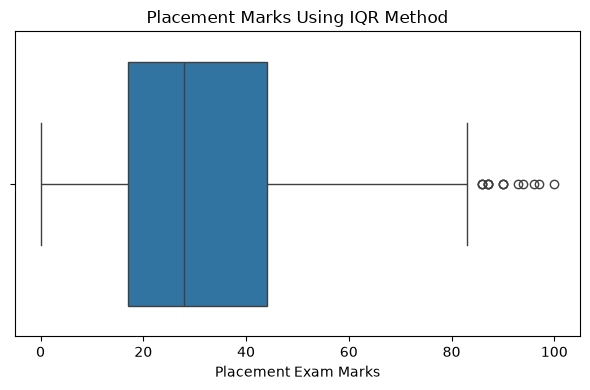

In [18]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=df["placement_exam_marks"])
plt.title("Placement Marks Using IQR Method")
plt.xlabel("Placement Exam Marks")
plt.tight_layout()
plt.show()

In [19]:
encoder = LabelEncoder()
df["placed"] = encoder.fit_transform(df["placed"])

print("Encoding Mapping: ")
for l, val in zip(encoder.classes_, encoder.transform(encoder.classes_)):
    print(f"{l}: {val}")

print("\nEncoded Data Sample:")
df.head(5)

Encoding Mapping: 
Not Placed: 0
Placed: 1

Encoded Data Sample:


,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
